In [1]:
# ============================================================
# DEPENDENCY INSTALLATION & UPGRADE
# ============================================================
# Upgrading datasets and huggingface_hub to resolve the HfUriError
!pip install -U datasets huggingface_hub transformers accelerate --quiet

# ============================================================
# BERT-BASED MULTI-CLASS SENTIMENT ANALYSIS
# Model: BERT-base-uncased
# Dataset: TweetEval - Sentiment
# Classes: Negative, Neutral, Positive
# ============================================================

import os
import json
import numpy as np
import torch
import matplotlib.pyplot as plt
import seaborn as sns

from datasets import load_dataset
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    DataCollatorWithPadding,
    TrainingArguments,
    Trainer,
    set_seed
)

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix,
    f1_score
)


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
cudf-cu13 26.6.0 requires pyarrow<24,>=19.0.0, but you have pyarrow 26.0.1 which is incompatible.


In [2]:
# ============================================================
# DEPENDENCY INSTALLATION & UPGRADE
# ============================================================
# Upgrading datasets and huggingface_hub to resolve the HfUriError
!pip install -U datasets huggingface_hub transformers accelerate --quiet

# ============================================================
# BERT-BASED MULTI-CLASS SENTIMENT ANALYSIS
# Model: BERT-base-uncased
# Dataset: TweetEval - Sentiment
# Classes: Negative, Neutral, Positive
# ============================================================

import os
import json
import numpy as np
import torch
import matplotlib.pyplot as plt
import seaborn as sns

from datasets import load_dataset
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    DataCollatorWithPadding,
    TrainingArguments,
    Trainer,
    set_seed
)

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix,
    f1_score
)


In [3]:

# ============================================================
# 1. CONFIGURATION
# ============================================================

MODEL_NAME = "bert-base-uncased"
DATASET_NAME = "cardiffnlp/tweet_eval"
DATASET_CONFIG = "sentiment"

MAX_LENGTH = 128
EPOCHS = 3
BATCH_SIZE = 16
LEARNING_RATE = 2e-5
SEED = 42

MODEL_DIR = "models/bert-sentiment-model"
OUTPUT_DIR = "outputs"

os.makedirs(MODEL_DIR, exist_ok=True)
os.makedirs(OUTPUT_DIR, exist_ok=True)

set_seed(SEED)

device = "cuda" if torch.cuda.is_available() else "cpu"

print("Device:", device)

Device: cuda


In [4]:

# ============================================================
# 2. LOAD DATASET
# ============================================================
from datasets import load_dataset

dataset = load_dataset(
    "cardiffnlp/tweet_eval",
    "sentiment"
)

train_data = dataset["train"]
validation_data = dataset["validation"]
test_data = dataset["test"]

print(dataset)

print("\nDataset loaded successfully!")

print("Training records:", len(train_data))
print("Validation records:", len(validation_data))
print("Testing records:", len(test_data))

# Get actual class names from dataset metadata

class_names = train_data.features["label"].names

num_labels = len(class_names)

id2label = {
    i: label for i, label in enumerate(class_names)
}

label2id = {
    label: i for i, label in enumerate(class_names)
}

print("\nClasses:", class_names)

README.md:   0%|          | 0.00/23.9k [00:00<?, ?B/s]

sentiment/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 3.78MB            

sentiment/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

sentiment/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  901kB            

sentiment/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

sentiment/validation-00000-of-00001.parq(…): reconstructing file:   0%|          |  0.00B /  167kB            

sentiment/validation-00000-of-00001.parq(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/45615 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/12284 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/2000 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 45615
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 12284
    })
    validation: Dataset({
        features: ['text', 'label'],
        num_rows: 2000
    })
})

Dataset loaded successfully!
Training records: 45615
Validation records: 2000
Testing records: 12284

Classes: ['negative', 'neutral', 'positive']


In [5]:
# ============================================================
# 3. CLASS DISTRIBUTION
# ============================================================

def show_class_distribution(data, split_name):

    labels = np.array(data["label"])

    counts = np.bincount(
        labels,
        minlength=num_labels
    )

    print(f"\n{split_name} Class Distribution:")

    for i, label in enumerate(class_names):
        percentage = counts[i] / len(labels) * 100

        print(
            f"{label}: {counts[i]} "
            f"({percentage:.2f}%)"
        )


show_class_distribution(train_data, "Training")
show_class_distribution(validation_data, "Validation")
show_class_distribution(test_data, "Testing")


Training Class Distribution:
negative: 7093 (15.55%)
neutral: 20673 (45.32%)
positive: 17849 (39.13%)

Validation Class Distribution:
negative: 312 (15.60%)
neutral: 869 (43.45%)
positive: 819 (40.95%)

Testing Class Distribution:
negative: 3972 (32.33%)
neutral: 5937 (48.33%)
positive: 2375 (19.33%)


In [6]:
# ============================================================
# 4. TOKENIZATION
# ============================================================

tok_name = MODEL_NAME
tokenizer = AutoTokenizer.from_pretrained(tok_name)


def tokenize_function(examples):

    return tokenizer(
        examples["text"],
        truncation=True,
        max_length=MAX_LENGTH
    )


tokenized_dataset = dataset.map(
    tokenize_function,
    batched=True
)

data_collator = DataCollatorWithPadding(
    tokenizer=tokenizer
)

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Map:   0%|          | 0/45615 [00:00<?, ? examples/s]

Map:   0%|          | 0/12284 [00:00<?, ? examples/s]

Map:   0%|          | 0/2000 [00:00<?, ? examples/s]

In [7]:
# ============================================================
# 5. LOAD PRETRAINED BERT MODEL
# ============================================================

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=num_labels,
    id2label=id2label,
    label2id=label2id
)

print("\nBERT model loaded successfully!")


model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.



BERT model loaded successfully!


In [8]:


# ============================================================
# 6. EVALUATION METRICS
# ============================================================

def compute_metrics(eval_pred):

    logits, labels = eval_pred

    predictions = np.argmax(logits, axis=-1)

    accuracy = accuracy_score(
        labels,
        predictions
    )

    precision_macro, recall_macro, f1_macro, _ = (
        precision_recall_fscore_support(
            labels,
            predictions,
            average="macro",
            zero_division=0
        )
    )

    precision_weighted, recall_weighted, f1_weighted, _ = (
        precision_recall_fscore_support(
            labels,
            predictions,
            average="weighted",
            zero_division=0
        )
    )

    return {
        "accuracy": accuracy,
        "precision_macro": precision_macro,
        "recall_macro": recall_macro,
        "f1_macro": f1_macro,
        "precision_weighted": precision_weighted,
        "recall_weighted": recall_weighted,
        "f1_weighted": f1_weighted
    }

In [9]:
# ============================================================
# 7. TRAINING CONFIGURATION
# ============================================================
import transformers
import inspect
from transformers import TrainingArguments

print("Transformers version:", transformers.__version__)
print(inspect.signature(TrainingArguments.__init__))
training_args = TrainingArguments(

    output_dir="training_checkpoints",

    num_train_epochs=EPOCHS,

    per_device_train_batch_size=BATCH_SIZE,

    per_device_eval_batch_size=BATCH_SIZE,

    learning_rate=LEARNING_RATE,

    weight_decay=0.01,

    eval_strategy="epoch",

    save_strategy="epoch",

    load_best_model_at_end=True,

    metric_for_best_model="f1_macro",

    greater_is_better=True,

    logging_steps=100,

    save_total_limit=2,

    report_to="none",

    seed=SEED,

    fp16=torch.cuda.is_available(),

    dataloader_num_workers=0
)

Transformers version: 5.23.0
(self, output_dir: str | None = None, per_device_train_batch_size: int = 8, num_train_epochs: float = 3.0, max_steps: int = -1, learning_rate: float = 5e-05, lr_scheduler_type: transformers.trainer_utils.SchedulerType | str = 'linear', lr_scheduler_kwargs: dict | str | None = None, warmup_steps: float = 0, optim: transformers.training_args.OptimizerNames | str = 'adamw_torch_fused', optim_args: str | None = None, weight_decay: float = 0.0, adam_beta1: float = 0.9, adam_beta2: float = 0.999, adam_epsilon: float = 1e-08, optim_target_modules: None | str | list[str] = None, gradient_accumulation_steps: int = 1, average_tokens_across_devices: bool = True, max_grad_norm: float = 1.0, label_smoothing_factor: float = 0.0, bf16: bool = False, fp16: bool = False, bf16_full_eval: bool = False, fp16_full_eval: bool = False, tf32: bool | None = None, activation_checkpointing: bool | None = None, activation_checkpointing_kwargs: dict[str, typing.Any] | str | None = None

In [10]:
# ============================================================
# 8. INITIALIZE TRAINER
# ============================================================

trainer = Trainer(

    model=model,

    args=training_args,

    train_dataset=tokenized_dataset["train"],

    eval_dataset=tokenized_dataset["validation"],

    processing_class=tokenizer,

    data_collator=data_collator,

    compute_metrics=compute_metrics
)

In [11]:
# ============================================================
# 9. MAJORITY-CLASS BASELINE
# ============================================================

train_labels = np.array(train_data["label"])

majority_class = np.bincount(
    train_labels,
    minlength=num_labels
).argmax()

test_labels = np.array(test_data["label"])

baseline_predictions = np.full(
    len(test_labels),
    majority_class
)

baseline_metrics = compute_metrics(
    (baseline_predictions.reshape(-1, 1), test_labels)
)

print("\nMajority Class Baseline:")
print(baseline_metrics)


Majority Class Baseline:
{'accuracy': 0.32334744382937153, 'precision_macro': 0.10778248127645718, 'recall_macro': 0.3333333333333333, 'f1_macro': 0.1628937007874016, 'precision_weighted': 0.10455356943098859, 'recall_weighted': 0.32334744382937153, 'f1_weighted': 0.15801378529653837}


In [12]:
# ============================================================
# 10. FINE-TUNE BERT
# ============================================================

print("\nStarting BERT fine-tuning...")

train_result = trainer.train()

print("\nTraining completed!")


Starting BERT fine-tuning...


Epoch,Training Loss,Validation Loss,Accuracy,Precision Macro,Recall Macro,F1 Macro,Precision Weighted,Recall Weighted,F1 Weighted
1,0.595284,0.592900,0.736500,0.738662,0.711379,0.720430,0.747500,0.736500,0.736775
2,0.489754,0.630645,0.749500,0.745677,0.714411,0.726331,0.748125,0.749500,0.746656
3,0.289621,0.786900,0.738000,0.720229,0.723470,0.721682,0.737337,0.738000,0.737468


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[transformers] There were missing keys in the checkpoint model loaded: ['bert.embeddings.LayerNorm.weight', 'bert.embeddings.LayerNorm.bias', 'bert.encoder.layer.0.attention.output.LayerNorm.weight', 'bert.encoder.layer.0.attention.output.LayerNorm.bias', 'bert.encoder.layer.0.output.LayerNorm.weight', 'bert.encoder.layer.0.output.LayerNorm.bias', 'bert.encoder.layer.1.attention.output.LayerNorm.weight', 'bert.encoder.layer.1.attention.output.LayerNorm.bias', 'bert.encoder.layer.1.output.LayerNorm.weight', 'bert.encoder.layer.1.output.LayerNorm.bias', 'bert.encoder.layer.2.attention.output.LayerNorm.weight', 'bert.encoder.layer.2.attention.output.LayerNorm.bias', 'bert.encoder.layer.2.output.LayerNorm.weight', 'bert.encoder.layer.2.output.LayerNorm.bias', 'bert.encoder.layer.3.attention.output.LayerNorm.weight', 'bert.encoder.layer.3.attention.output.LayerNorm.bias', 'bert.encoder.layer.3.output.LayerNorm.weight', 'bert.encoder.layer.3.output.LayerNorm.bias', 'bert.encoder.layer.4.atte


Training completed!


In [13]:
# ============================================================
# 11. TEST SET EVALUATION
# ============================================================

test_results = trainer.predict(
    tokenized_dataset["test"]
)

predictions = np.argmax(
    test_results.predictions,
    axis=-1
)

actual_labels = test_results.label_ids

final_metrics = compute_metrics(
    (test_results.predictions, actual_labels)
)

print("\nFinal Test Results:")

for metric, value in final_metrics.items():

    print(f"{metric}: {value:.4f}")


Final Test Results:
accuracy: 0.6737
precision_macro: 0.6736
recall_macro: 0.6824
f1_macro: 0.6698
precision_weighted: 0.6856
recall_weighted: 0.6737
f1_weighted: 0.6734


In [14]:
# ============================================================
# 12. CLASSIFICATION REPORT
# ============================================================

report = classification_report(
    actual_labels,
    predictions,
    labels=list(range(num_labels)),
    target_names=class_names,
    zero_division=0
)

print("\nClassification Report:")
print(report)

with open(
    f"{OUTPUT_DIR}/classification_report.txt",
    "w"
) as file:

    file.write(report)


Classification Report:
              precision    recall  f1-score   support

    negative       0.76      0.58      0.66      3972
     neutral       0.68      0.70      0.69      5937
    positive       0.58      0.77      0.66      2375

    accuracy                           0.67     12284
   macro avg       0.67      0.68      0.67     12284
weighted avg       0.69      0.67      0.67     12284



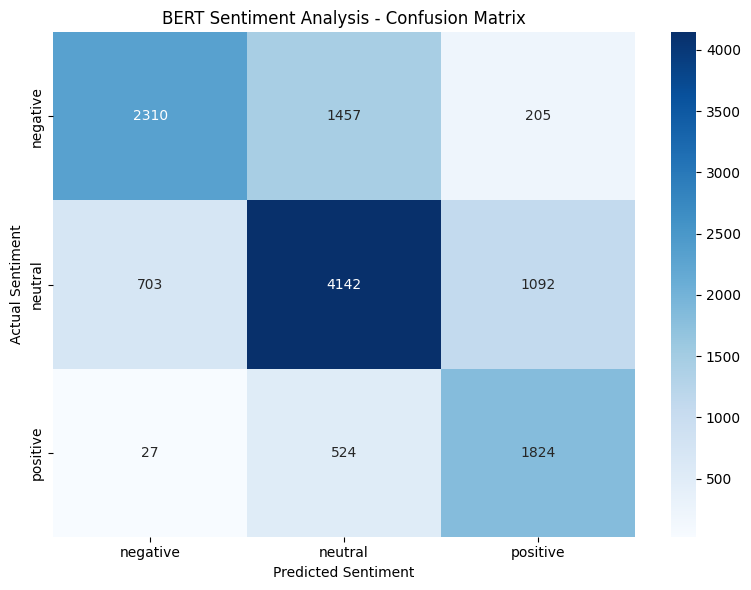

In [15]:
# ============================================================
# 13. CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(
    actual_labels,
    predictions,
    labels=list(range(num_labels))
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Sentiment")
plt.ylabel("Actual Sentiment")
plt.title("BERT Sentiment Analysis - Confusion Matrix")

plt.tight_layout()

plt.savefig(
    f"{OUTPUT_DIR}/confusion_matrix.png",
    dpi=300
)

plt.show()

In [16]:
# ============================================================
# 14. SAVE EVALUATION METRICS
# ============================================================

results = {

    "model": MODEL_NAME,

    "dataset": DATASET_NAME,

    "dataset_config": DATASET_CONFIG,

    "classes": class_names,

    "train_records": len(train_data),

    "validation_records": len(validation_data),

    "test_records": len(test_data),

    "baseline": baseline_metrics,

    "bert_test_metrics": final_metrics
}

with open(
    f"{OUTPUT_DIR}/metrics.json",
    "w"
) as file:

    json.dump(
        results,
        file,
        indent=4
    )

In [17]:
# ============================================================
# 15. SAVE FINE-TUNED MODEL
# ============================================================

trainer.save_model(MODEL_DIR)

tokenizer.save_pretrained(MODEL_DIR)

print("\nModel saved successfully at:", MODEL_DIR)


print("\n================================")
print("PROJECT EXECUTION COMPLETED")
print("================================")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


Model saved successfully at: models/bert-sentiment-model

PROJECT EXECUTION COMPLETED


In [18]:

# ============================================================
# BERT SENTIMENT ANALYSIS - INFERENCE
# ============================================================

import torch

from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification
)

MODEL_DIR = "models/bert-sentiment-model"

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# Load saved tokenizer

tokenizer = AutoTokenizer.from_pretrained(
    MODEL_DIR
)

# Reload fine-tuned model

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_DIR
)

model.to(device)
model.eval()


# ============================================================
# SENTIMENT PREDICTION FUNCTION
# ============================================================

def predict_sentiment(text):

    inputs = tokenizer(
        text,
        return_tensors="pt",
        truncation=True,
        max_length=128
    )

    inputs = {
        key: value.to(device)
        for key, value in inputs.items()
    }

    with torch.no_grad():

        outputs = model(**inputs)

        probabilities = torch.softmax(
            outputs.logits,
            dim=-1
        )

        predicted_class = torch.argmax(
            probabilities,
            dim=-1
        ).item()

    sentiment = model.config.id2label[
        predicted_class
    ]

    confidence = probabilities[0][
        predicted_class
    ].item()

    return {
        "text": text,
        "sentiment": sentiment,
        "confidence": round(confidence, 4)
    }


# ============================================================
# TEST NEW TEXT INPUTS
# ============================================================

sample_texts = [

    "I absolutely love this product!",

    "This is the worst experience I have ever had.",

    "The product is okay, nothing special.",

    "The service was excellent and delivery was fast.",

    "I am disappointed with the overall experience."
]


for text in sample_texts:

    result = predict_sentiment(text)

    print("\nText:", result["text"])

    print("Sentiment:", result["sentiment"])

    print("Confidence:", result["confidence"])

    print("-" * 50)


# ============================================================
# INTERACTIVE PREDICTION
# ============================================================

while True:

    user_text = input(
        "\nEnter text (or type 'exit' to quit): "
    )

    if user_text.lower() == "exit":
        break

    result = predict_sentiment(user_text)

    print("Predicted Sentiment:", result["sentiment"])

    print("Confidence:", result["confidence"])


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]


Text: I absolutely love this product!
Sentiment: positive
Confidence: 0.9935
--------------------------------------------------

Text: This is the worst experience I have ever had.
Sentiment: negative
Confidence: 0.9866
--------------------------------------------------

Text: The product is okay, nothing special.
Sentiment: positive
Confidence: 0.8558
--------------------------------------------------

Text: The service was excellent and delivery was fast.
Sentiment: positive
Confidence: 0.9912
--------------------------------------------------

Text: I am disappointed with the overall experience.
Sentiment: negative
Confidence: 0.979
--------------------------------------------------

Enter text (or type 'exit' to quit): I am very happy with the delivery
Predicted Sentiment: positive
Confidence: 0.9932

Enter text (or type 'exit' to quit): exit


In [19]:

# ============================================================
# MAJORITY-CLASS BASELINE
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support
)

train_labels = np.array(train_data["label"])

majority_class = np.bincount(
    train_labels,
    minlength=num_labels
).argmax()

test_labels = np.array(test_data["label"])

baseline_predictions = np.full(
    len(test_labels),
    majority_class
)

baseline_precision_macro, baseline_recall_macro, baseline_f1_macro, _ = (
    precision_recall_fscore_support(
        test_labels,
        baseline_predictions,
        average="macro",
        zero_division=0
    )
)

baseline_precision_weighted, baseline_recall_weighted, baseline_f1_weighted, _ = (
    precision_recall_fscore_support(
        test_labels,
        baseline_predictions,
        average="weighted",
        zero_division=0
    )
)

baseline_metrics = {
    "accuracy": accuracy_score(
        test_labels, baseline_predictions
    ),
    "precision_macro": baseline_precision_macro,
    "recall_macro": baseline_recall_macro,
    "f1_macro": baseline_f1_macro,
    "precision_weighted": baseline_precision_weighted,
    "recall_weighted": baseline_recall_weighted,
    "f1_weighted": baseline_f1_weighted
}

print("\nMajority Class Baseline:")

for metric, value in baseline_metrics.items():
    print(f"{metric}: {value:.4f}")



Majority Class Baseline:
accuracy: 0.4833
precision_macro: 0.1611
recall_macro: 0.3333
f1_macro: 0.2172
precision_weighted: 0.2336
recall_weighted: 0.4833
f1_weighted: 0.3150
